### To build deep learning ; we have 2 libraries 
    Tensorflow - Old library
    Keras 3 - (Independent of tensorflow)

In [1]:
import tensorflow as tf
from tensorflow import keras
import pandas as pd
from matplotlib import pyplot as plt

#### Import necessary libraries:

In [2]:
import keras

#### Data collection:

In [5]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

#### Data Understanding:

In [6]:
X_train.shape ,y_train.shape 

((60000, 28, 28), (60000,))

In [7]:
X_test.shape,y_test.shape

((10000, 28, 28), (10000,))

#### How one image look like:

In [8]:
pd.DataFrame(data=X_train[10000])

,0,1,2,3,4,5,6,7,8,9,...,18,19,20,21,22,23,24,25,26,27
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,29,...,96,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,48,166,224,...,233,0,0,0,0,0,0,0,0,0
7,0,0,0,0,0,93,244,249,253,187,...,233,0,0,0,0,0,0,0,0,0
8,0,0,0,0,0,107,253,253,230,48,...,156,0,0,0,0,0,0,0,0,0
9,0,0,0,0,0,3,20,20,15,0,...,74,0,0,0,0,0,0,0,0,0


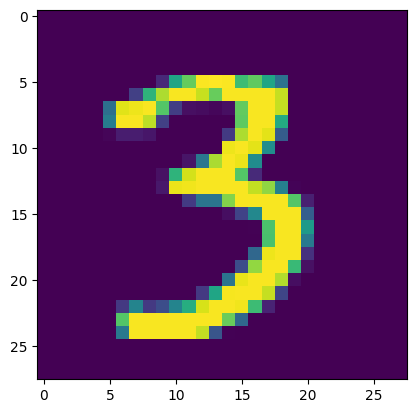

In [9]:
plt.imshow(X_train[10000])

#### Data Preparation:

In [10]:
X_train.mean(),X_train.std()

(np.float64(33.318421449829934), np.float64(78.56748998339798))

In [12]:
X_test.mean(),X_test.std()

(np.float64(33.791224489795916), np.float64(79.17246322228644))

##### let's normalize this for faster processing:

In [13]:
X_train = X_train/255.0
X_test = X_test/255.0

In [14]:
X_train.min(),X_train.max()

(np.float64(0.0), np.float64(1.0))

In [15]:
X_test.min(),X_test.max()

(np.float64(0.0), np.float64(1.0))

In [16]:
pd.DataFrame(data=X_train[10000])

,0,1,2,3,4,5,6,7,8,9,...,18,19,20,21,22,23,24,25,26,27
0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.113725,...,0.376471,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.188235,0.650980,0.878431,...,0.913725,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,0.0,0.0,0.0,0.0,0.0,0.364706,0.956863,0.976471,0.992157,0.733333,...,0.913725,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,0.0,0.0,0.0,0.0,0.0,0.419608,0.992157,0.992157,0.901961,0.188235,...,0.611765,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,0.0,0.0,0.0,0.0,0.0,0.011765,0.078431,0.078431,0.058824,0.000000,...,0.290196,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0


#### Model Building :

In [17]:
from keras.models import Sequential 
from keras.layers import Flatten
from keras.layers import Dense

In [42]:
model=Sequential()
model.add(Flatten(input_shape=(28,28)))
model.add(Dense(units=100,activation="relu"))
model.add(Dense(units=50,activation="relu"))
model.add(Dense(units=10,activation="softmax"))
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_5 (Flatten)                  │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 100)                 │          78,500 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 50)                  │           5,050 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_12 (Dense)                     │ (None, 10)                  │             510 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 84,060 (328.36 KB)

 Trainable params: 84,060 (328.36 KB)

 Non-trainable params: 0 (0.00 B)

In [44]:
model.compile(optimizer='rmsprop',loss="sparse_categorical_crossentropy",metrics=["sparse_categorical_accuracy"])

#### Model training | Model testing | Model Evaluation :

In [45]:
model.fit(x=X_train,y=y_train,batch_size=32,epochs=10,validation_data=(X_test,y_test))

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 0.2512 - sparse_categorical_accuracy: 0.9258 - val_loss: 0.1252 - val_sparse_categorical_accuracy: 0.9607
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 0.1116 - sparse_categorical_accuracy: 0.9670 - val_loss: 0.0962 - val_sparse_categorical_accuracy: 0.9689
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 0.0835 - sparse_categorical_accuracy: 0.9751 - val_loss: 0.0834 - val_sparse_categorical_accuracy: 0.9749
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 0.0689 - sparse_categorical_accuracy: 0.9800 - val_loss: 0.0867 - val_sparse_categorical_accuracy: 0.9754
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 0.0569 - sparse_categorical_accuracy: 0.9833 - val_loss: 0.0969 - val_sparse_categorical_accuracy: 0.9721
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 0.0489 - sparse_categorical_accuracy: 0.9862 - val_loss: 0.0964 - val_sparse_categorical_accuracy:

In [46]:
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_5 (Flatten)                  │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 100)                 │          78,500 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 50)                  │           5,050 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_12 (Dense)                     │ (None, 10)                  │             510 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 168,122 (656.73 KB)

 Trainable params: 84,060 (328.36 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 84,062 (328.37 KB)

#### Model Prediction:

In [48]:
y_pred=model.predict(X_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [49]:
y_test[1000]

np.uint8(2)

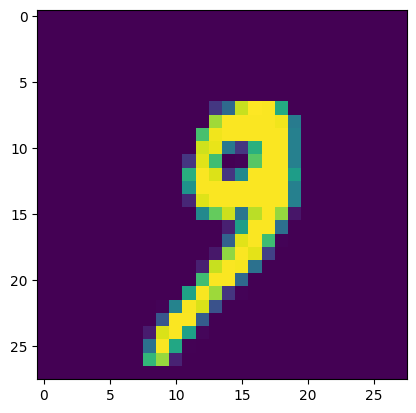

In [54]:
plt.imshow(X_test[1000])

In [51]:
import numpy as np

In [53]:
np.argmax(y_pred[1000])

np.int64(9)

================================================================================================================================

#### Let's test for outside new data:

### Step :1  Let's take out the model intelligence file:

In [59]:
model.save(filepath="digits_intel.h5")

### Step :2 Image load:

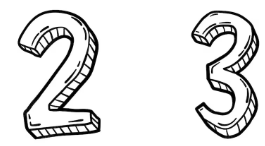

In [78]:
from PIL import Image
Image_path=r"C:\Users\parth\OneDrive\Pictures\Screenshots\Screenshot 2026-10-06 205617.png"
Image = Image.open(Image_path)
Image=Image.convert('L')
Image.resize(size=(28,28))
Image.size
Image


### Step :3 

In [79]:
from keras.models import load_model
digits_brain = load_model("digits_intel.h5")

=================================================================================================================================